<a href="https://colab.research.google.com/github/RiccardoNesca/astrostatistics_bicocca_2026/blob/main/working/ES7_irreduciblemass.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## The irreducible mass of black holes.


For a BH of mass $M$ spin $\chi\in [0,1]$, the irreducible mass is
$$
M_{\rm irr} = %\sqrt{\frac{M^2+\sqrt{M^4-S^2}}{2}} =
 M \sqrt{\frac{1+\sqrt{1-\chi^2}}{2}}
$$
For convenience, let us define

$$f(\chi) = \sqrt{\frac{1+\sqrt{1-\chi^2}}{2}}$$

Suppose you have repeated measurments of $M$ and $\chi$. This is just because we're still frequentists for now. When we will put our Bayesian hat on, these distributions will be the *posterior samples* from a single measurement.

Let's assume that

- the spin $\chi$ is uniformly distributed between 0 and 1.
- the mass $M$ is normally distributed with mean $\mu$ and standard deviation $\sigma$.
- (masses and spins are uncorrelated)


**Tasks**:

1. Start with a value of $\sigma=0.02$. Note that $\mu$ is a scale and not a parameter: you can normalize all quantities with a dimension of mass by $\mu$. Just set $\mu=1$ in your code and remember that all masses in the problem are measured in units of $\mu$.

2. Plot the resulting pdf of $M_{\rm irr}$. First try an histogram with one the rules of thumb we've seen above.

In [243]:
import numpy as np
import scipy as sp
import matplotlib.axes as mpl
import pylab as plt
import sklearn as skl


In [244]:
def fchi(chi):
  return ((1+(1-chi**2)**0.5)/2)**0.5
def Mass(mu,sigma,N):
  return sp.stats.norm.rvs(mu,sigma,N)

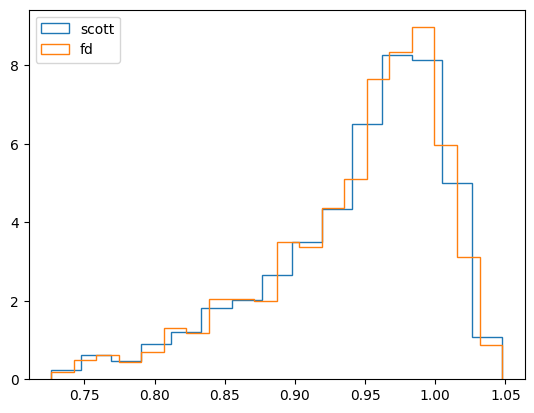

In [245]:
sigma_fixed=0.02
mu_fixed=1


#Mirr pdf empirically
N=1000 #number of sample generated

chi= np.random.uniform(0,1,N) #spin
f_chi=fchi(chi)

M=Mass(mu_fixed,sigma_fixed,N) #mass

M_irr=M*f_chi

#plot
plt.hist(M_irr,bins='scott',density=True,histtype="step",label='scott')
plt.hist(M_irr,bins='fd',density=True,histtype="step",label='fd')
plt.legend()
plt.show()

3. Using the same samples, plot the distribution of $M_{\rm irr}$ using a KDE.


In [246]:
from sklearn.neighbors import KernelDensity
xgrid = np.linspace(M_irr.min(),M_irr.max(),N)

def kde_sklearn(data, bandwidth, kernel):
    xgrid = np.linspace(data.min(),data.max(),N)
    kde_skl = KernelDensity(bandwidth = bandwidth,
                            kernel=kernel)
    kde_skl.fit(data[:, np.newaxis])
    log_pdf = kde_skl.score_samples(xgrid[:, np.newaxis]) # sklearn returns log(density)
    return np.exp(log_pdf)

*  KDE EPANECHINKOV with variable bandwidth

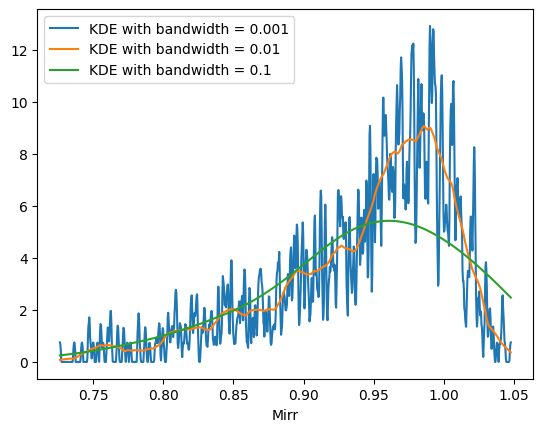

In [247]:
bandwidth=[0.001,0.01,0.1]
label=["0.001","0.01","0.1"]
for band,label in zip(bandwidth,label):
  kde_epan=kde_sklearn(M_irr,band,"epanechnikov")
  plt.plot(xgrid,kde_epan,label=f"KDE with bandwidth = {label}")
plt.legend()
plt.xlabel("Mirr")
plt.show()

*  KDE with various kernel

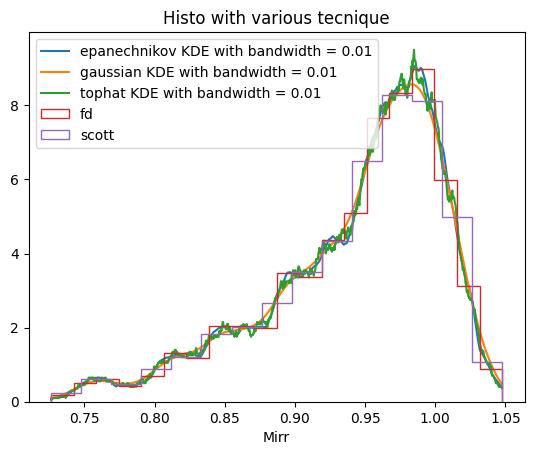

In [248]:
kd=['epanechnikov','gaussian','tophat']

for kd in kd:
  kde_epan=kde_sklearn(M_irr,0.01,kd)
  plt.plot(xgrid,kde_epan,label=f"{kd} KDE with bandwidth = 0.01")

plt.hist(M_irr,bins='fd',density=True,histtype="step",label='fd')
plt.hist(M_irr,bins='scott',density=True,histtype="step",label='scott')

plt.legend()
plt.title('Histo with various tecnique')
plt.xlabel("Mirr")
plt.show()

4. Compute the KS distance between ${M_{\rm irr}}/\mu$ and ${f}$ as a function of $\sigma$. Discuss the limits at large and small values of $\sigma$.
5. Compute the KS distance between ${M_{\rm irr}}$ and $M$ as a function of $\sigma$. Discuss the limits at large and small values of $\sigma$.

<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:22: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:22: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_3711/575411501.py:18: SyntaxWarning: invalid escape sequence '\s'
  plt.axvline(x=mu_fixed,label='$\sigma = \mu$',color='red',linestyle='--')
/tmp/ipykernel_3711/575411501.py:22: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel("$\sigma$")
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  res = hypotest_fun_out(*samples, **kwds)


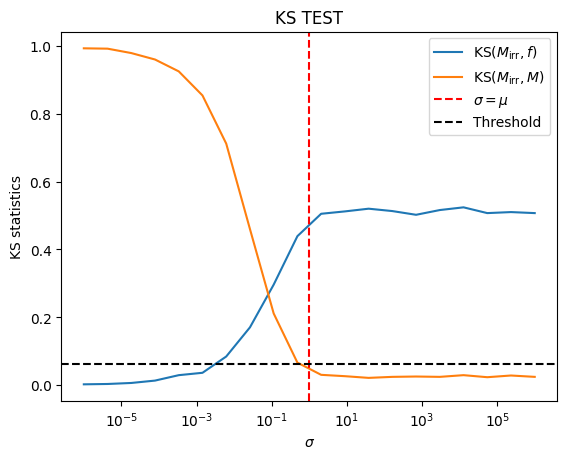

In [249]:
sigmas= np.logspace(-6,6,20) #exploring the sigmas scale
KS_f=[]
KS_M=[]

ne=N/2 #effective number of Data point for sample with same N
DKS= 1.36/(ne)**0.5 #D threshold at CL 95% for ne>10

for sigma in sigmas:
  M=Mass(mu_fixed,sigma,N)
  KS_f.append(sp.stats.ks_2samp(M*f_chi,f_chi).statistic)
  KS_M.append(sp.stats.ks_2samp(M*f_chi,M).statistic)



#plot
plt.plot(sigmas,KS_f,label="KS$(M_{\\rm irr}, f)$")
plt.plot(sigmas,KS_M,label='KS$(M_{\\rm irr}, M)$')
plt.axvline(x=mu_fixed,label='$\sigma = \mu$',color='red',linestyle='--')
plt.axhline(y=DKS,label='Threshold',color='black',linestyle='--')

plt.xscale('log')
plt.xlabel("$\sigma$")
plt.ylabel('KS statistics')
plt.legend()
plt.title('KS TEST')
plt.show()


9. Using the expressions from point 7 and 8, plot those pdfs check that they agree with your KDE reconstructions.

*  \begin{equation}
\pi(f) = 2\frac{2 f^2-1}{\sqrt{1 - f^2}}\,
\end{equation}

*  
$$p(M_{\rm irr})  = \frac{\sqrt{2/\pi}}{\sigma} \int_{1/\sqrt{2}}^1 \exp\left[{-\frac{(M_{\rm irr}/f-\mu)^2}{2\sigma^2}}\right]  \frac{2 f^2-1}{f \sqrt{1 - f^2}}  \,\, {\rm d}f\, $$


In [250]:
def pdff(f):
  return 2*(2*f**2-1)/(1 - f**2)**0.5

def integrand(f, M_irr, mu, sigma):
    return np.exp(-(M_irr/f - mu)**2 / (2*sigma**2)) * (2*f**2 - 1) / (f * np.sqrt(1 - f**2))

def pdf_Mirr(M_irr, mu, sigma):
    result, _ = sp.integrate.quad(lambda f: integrand(f, M_irr, mu, sigma), 1/np.sqrt(2), 1)
    return np.sqrt(2/np.pi) / sigma * result

<>:11: SyntaxWarning: invalid escape sequence '\c'
<>:11: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_3711/3579560471.py:11: SyntaxWarning: invalid escape sequence '\c'
  plt.xlabel("$\chi$")
/tmp/ipykernel_3711/3479389148.py:2: RuntimeWarning: divide by zero encountered in divide
  return 2*(2*f**2-1)/(1 - f**2)**0.5


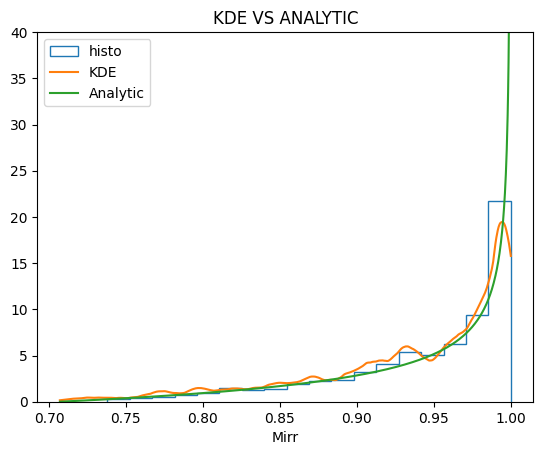

In [251]:
#f(chi)

xgrid1=np.linspace(1/np.sqrt(2), 1,N)
kde_f=kde_sklearn(f_chi,0.01,"epanechnikov")
pdf_f=pdff(xgrid1)

#plot
plt.hist(f_chi,density=True,histtype='step',label='histo',bins='fd')
plt.plot(xgrid1,kde_f,label="KDE")
plt.plot(xgrid1,pdf_f,label="Analytic")
plt.xlabel("$\chi$")
plt.legend()
plt.ylim(0, 40)
plt.xlabel("f")

plt.title('KDE VS ANALYTIC')
plt.show()




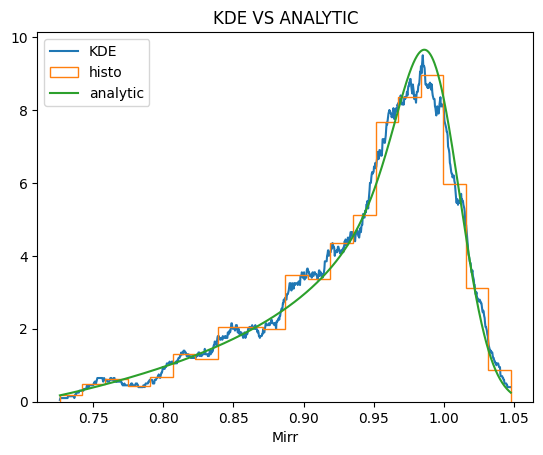

In [252]:
#Mirr

pdf_mass=[pdf_Mirr(Mirr_val, mu_fixed, sigma_fixed) for Mirr_val in xgrid]
#plot
plt.plot(xgrid,kde_epan,label="KDE")
plt.hist(M_irr,bins='fd',density=True,histtype="step",label='histo')
plt.plot(xgrid,pdf_mass,label='analytic')
plt.legend()
plt.xlabel("Mirr")
plt.title('KDE VS ANALYTIC')


plt.show()
